# Exact Adversarial Metrics - reproducibility notebook

Experiments for *Exact Adversarial Metrics: Scalable Fairness Attacks on
Clustering-Based Decisions and Committed Audits* (extended version of the
SECRYPT 2026 paper). Each experiment cell is the repository script with the
`__file__` paths and `__main__` guard adapted for the notebook. Running the
notebook top to bottom writes JSON result files into `../results` and renders
the paper's tables and figures inline.

| Cell | Paper | Produces |
|---|---|---|
| Modules | Sections 4–5 | `exactmetric.py`, `adm_port.py`, `datasets.py` |
| E0 | Section 4.4, Tables 1–2 | `results/e0.json` |
| E1 | Section 6.2, Table 3 | `results/e1.json` |
| E2 | Section 6.3, Table 4 | `results/e2.json` |
| E3 | Section 6.4, Table 5, Fig. 1 | `results/e3.json` |
| E4 | Section 6.5, Table 6, Fig. 2 | `results/e4.json` |

**Dependencies.** `numpy`, `scipy`, `scikit-learn >= 1.9` (for `HDBSCAN`),
`pandas`, `matplotlib`, `kmedoids` (FasterPAM).

**Data.** Unzip the provided `data.zip` into the project folder so the files
land under `<project>/data/`. That gives the three benchmarks and the two
conference artefacts (`As_m12_double.mat`, `As_m32_double.mat`) with no network
access. The setup cell also tries to download the benchmarks as a fallback, but
it never requires the network when the files are already present, and it prints
instructions rather than crashing when a download is blocked. E0 Part A needs
the two `.mat` artefacts; it skips to the self-contained Part B when they are
absent.

`numpy`'s Mersenne Twister reproduces MATLAB's `rng(seed)` for positive seeds,
so `adm_port.py` reproduces the conference construction exactly.

## Environment and data

In [1]:
import sys, subprocess, os, ssl, shutil, urllib.request

for pkg in ["numpy", "scipy", "scikit-learn", "pandas", "matplotlib", "kmedoids"]:
    try:
        __import__("sklearn" if pkg == "scikit-learn" else pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import sklearn
print("scikit-learn", sklearn.__version__)

# joblib looks up the number of physical cores through `wmic`, which Windows 11
# no longer ships. The lookup fails and prints a harmless traceback the first
# time scikit-learn asks for it (spectral clustering in E2). Seeding joblib's
# cache skips the lookup. LOKY_MAX_CPU_COUNT does not help unless it is set
# below the logical core count.
try:
    from joblib.externals.loky.backend import context as _loky_ctx
    if getattr(_loky_ctx, "physical_cores_cache", None) is None:
        try:
            import psutil
            _phys = psutil.cpu_count(logical=False)
        except Exception:
            _phys = None
        _loky_ctx.physical_cores_cache = _phys or os.cpu_count() or 1
except Exception:
    pass

# Project layout: <root>/code (modules), <root>/data, <root>/results. This
# matches datasets.py, which resolves DATA as <its own folder>/../data.
# The root is fixed once per kernel and strips any trailing `code` folders, so
# re-running this cell, or opening the notebook from inside code/, never nests
# code/code/... directories.
if "NB_ROOT" not in globals():
    _start = os.path.abspath(os.getcwd())
    NB_ROOT = _start
    while os.path.basename(NB_ROOT).lower() == "code":
        NB_ROOT = os.path.dirname(NB_ROOT)
os.makedirs(os.path.join(NB_ROOT, "code"), exist_ok=True)
os.chdir(os.path.join(NB_ROOT, "code"))
os.makedirs("../data/artifacts", exist_ok=True)
os.makedirs("../results", exist_ok=True)
DATA = os.path.abspath("../data")


def find_local(name):
    """Look for a file left elsewhere in the project (e.g. by an earlier run), or
    in a data/ folder beside the project (searched only two levels deep)."""
    for top, max_depth in ((NB_ROOT, 4), (os.path.dirname(NB_ROOT), 2)):
        base = top.rstrip(os.sep).count(os.sep)
        for dirpath, dirnames, filenames in os.walk(top):
            if dirpath.count(os.sep) - base >= max_depth:
                dirnames[:] = []
            if name in filenames:
                hit = os.path.join(dirpath, name)
                if os.path.abspath(os.path.dirname(hit)) not in (DATA, os.path.join(DATA, "artifacts")):
                    return hit
    return None


# The two conference artefacts for E0 Part A: copy them in if they sit elsewhere.
for art in ("As_m12_double.mat", "As_m32_double.mat"):
    dest = os.path.join(DATA, "artifacts", art)
    if not os.path.exists(dest):
        src = find_local(art)
        if src:
            shutil.copy2(src, dest); print("copied", art, "from", src)
print("E0 artefacts present:", all(os.path.exists(os.path.join(DATA, "artifacts", a))
                                  for a in ("As_m12_double.mat", "As_m32_double.mat")))

# Downloads are a best-effort fallback. With no internet or behind a firewall,
# unzip the provided data.zip into the project folder so the files appear under
# <project>/data/. The notebook never needs the network when they are present.
SOURCES = {
    "adult.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    "german.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data",
    "compas-scores-two-years.csv":
        "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv",
}

def fetch(url, dest):
    try:
        opener = urllib.request.build_opener(
            urllib.request.ProxyHandler(urllib.request.getproxies()),
            urllib.request.HTTPSHandler(context=ssl.create_default_context()))
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with opener.open(req, timeout=60) as r, open(dest, "wb") as f:
            f.write(r.read())
        return os.path.getsize(dest) > 0
    except Exception as e:
        print("   download failed:", type(e).__name__, e)
        return False

missing = []
for fname, url in SOURCES.items():
    path = os.path.join(DATA, fname)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        print("have", fname); continue
    src = find_local(fname)
    if src and os.path.getsize(src) > 0:
        shutil.copy2(src, path); print("copied", fname, "from", src); continue
    print("downloading", fname, "...")
    if fetch(url, path):
        print("  saved", fname)
    else:
        missing.append(fname)

if missing:
    print("\n" + "=" * 70)
    print("Could not obtain:", ", ".join(missing))
    print("Place these public dataset files in:\n   " + DATA)
    print("Easiest: unzip the provided data.zip into the project folder so the")
    print("files land under <project>/data/ (datasets and the two .mat artefacts).")
    print("Sources: Adult and German Credit from the UCI ML Repository;")
    print("COMPAS from github.com/propublica/compas-analysis.")
    print("=" * 70)
else:
    print("all datasets present")
print("working directory:", os.getcwd(), "| data:", DATA)

scikit-learn 1.5.1
E0 artefacts present: True
have adult.data
have german.data
have compas-scores-two-years.csv
all datasets present
working directory: C:\Users\Shahzad\Secure Systems\Exact_Adversarial_Metrics_code_resultsV2\code | data: C:\Users\Shahzad\Secure Systems\Exact_Adversarial_Metrics_code_resultsV2\data


## Modules

### `exactmetric.py` — exact adversarial metrics (Section 5)

`ExactExtension` is the McShane/Fréchet extension of a finite metric `R` on the
data `Y`: $\Phi_k(x)=\min_j(R_{jk}+L\,\lVert x-y_j\rVert)$ and
$d(x,y)=\max(\lVert\Phi(x)-\Phi(y)\rVert_\infty,\ \eta\lVert x-y\rVert)$. With
$L\ge L^\ast=\max R_{ij}/E_{ij}$ and $\eta\le\eta^\ast=\min R_{ij}/E_{ij}$ it is
a metric on $\mathbb{R}^\ell$, equals `R` on `Y`, and has distortion $L/\eta$
(optimal at $L^\ast,\eta^\ast$). `TwoLevelExtension` specialises this to the
two-level target with an $O(m)$ evaluation of $\Phi$.

In [2]:
%%writefile exactmetric.py
"""Exact adversarial metrics on R^ell.

ExactExtension: McShane/Frechet extension of a finite metric R on Y.
    Phi_k(x) = min_j ( R[j,k] + L ||x - y_j|| )
    d(x, y)  = max( ||Phi(x) - Phi(y)||_inf , eta ||x - y|| )
With L >= L* = max R_ij/E_ij and eta <= eta* = min R_ij/E_ij this is a metric on
R^ell, equals R on Y, and satisfies eta E <= d <= L E (optimal for L = L*, eta = eta*).

TwoLevelExtension: the same construction for the two-level target
    R_ij = s (same label), D (different label), 0 (i = j)
with an O(m) evaluation of Phi.
"""
import numpy as np


def pdist_matrix(X, Z=None, chunk=2048):
    """Euclidean distance matrix, computed in row chunks."""
    X = np.asarray(X, float)
    Z = X if Z is None else np.asarray(Z, float)
    out = np.empty((len(X), len(Z)))
    zz = (Z * Z).sum(1)
    for a in range(0, len(X), chunk):
        Xa = X[a:a + chunk]
        sq = (Xa * Xa).sum(1)[:, None] + zz[None, :] - 2.0 * Xa @ Z.T
        np.maximum(sq, 0.0, out=sq)
        out[a:a + chunk] = np.sqrt(sq)
    if Z is X:
        np.fill_diagonal(out, 0.0)
    return out


def lipschitz_constants(R, E):
    """L* and eta* of a target R relative to the Euclidean matrix E."""
    iu = np.triu_indices(len(R), 1)
    ratio = R[iu] / E[iu]
    return float(ratio.max()), float(ratio.min())


def triangle_defect(R):
    """tau(R) = max_{i,j,k} R_ij - R_ik - R_kj (vectorised over k)."""
    best = -np.inf
    for k in range(len(R)):
        V = R - R[:, [k]] - R[[k], :]
        V[k, :] = -np.inf
        V[:, k] = -np.inf
        np.fill_diagonal(V, -np.inf)
        best = max(best, float(V.max()))
    return best


class ExactExtension:
    def __init__(self, Y, R, E=None):
        self.Y = np.asarray(Y, float)
        self.R = np.asarray(R, float)
        E = pdist_matrix(self.Y) if E is None else E
        self.L, self.eta = lipschitz_constants(self.R, E)

    def phi(self, x):
        r = self.L * np.sqrt(((self.Y - x) ** 2).sum(1))
        return np.min(self.R + r[:, None], axis=0)

    def phi_many(self, X):
        return np.array([self.phi(x) for x in np.asarray(X, float)])

    def __call__(self, x, y):
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        return max(float(np.abs(self.phi(x) - self.phi(y)).max()),
                   self.eta * float(np.linalg.norm(x - y)))

    def matrix(self, X):
        """d on an arbitrary finite set X (rows)."""
        from scipy.spatial.distance import cdist
        P = self.phi_many(X)
        D = cdist(P, P, "chebyshev")
        return np.maximum(D, self.eta * pdist_matrix(X))


class TwoLevelExtension:
    """Exact metric realising the two-level target of a labelling."""

    def __init__(self, Y, labels, s, D, optimal=True):
        self.Y = np.asarray(Y, float)
        self.lab = np.asarray(labels)
        self.s, self.D = float(s), float(D)
        self.classes = np.unique(self.lab)
        if optimal:
            self.L, self.eta = self._constants_exact()
        else:
            self.L, self.eta = self._constants_fast()

    def _constants_exact(self, chunk=512):
        """L* and eta* in O(m^2) time and O(chunk * m) memory."""
        m = len(self.Y)
        L, eta = 0.0, np.inf
        zz = (self.Y ** 2).sum(1)
        for a in range(0, m, chunk):
            Ya = self.Y[a:a + chunk]
            sq = (Ya ** 2).sum(1)[:, None] + zz[None, :] - 2.0 * Ya @ self.Y.T
            np.maximum(sq, 0.0, out=sq)
            E = np.sqrt(sq)
            same = self.lab[a:a + chunk, None] == self.lab[None, :]
            idx = np.arange(a, min(a + chunk, m))
            E[np.arange(len(idx)), idx] = np.nan
            T = np.where(same, self.s, self.D) / E
            L = max(L, float(np.nanmax(T)))
            eta = min(eta, float(np.nanmin(T)))
        return L, eta

    def _constants_fast(self):
        """Valid (not optimal) constants in O(m log m): closest pair and a diameter bound."""
        from scipy.spatial import cKDTree
        tree = cKDTree(self.Y)
        dd, _ = tree.query(self.Y, k=2)
        dmin = float(dd[:, 1].min())
        diam = 2.0 * float(np.sqrt(((self.Y - self.Y.mean(0)) ** 2).sum(1)).max())
        return max(self.s, self.D) / dmin, min(self.s, self.D) / diam

    def rho(self):
        R = np.where(self.lab[:, None] == self.lab[None, :], self.s, self.D)
        np.fill_diagonal(R, 0.0)
        return R

    def phi(self, x):
        e = self.L * np.sqrt(((self.Y - x) ** 2).sum(1))
        out = np.empty(len(self.Y))
        for c in self.classes:
            idx = np.flatnonzero(self.lab == c)
            ec = e[idx]
            o = np.argsort(ec)[:2]
            first, arg1 = ec[o[0]], idx[o[0]]
            second = ec[o[1]] if len(o) > 1 else np.inf
            others = e[self.lab != c]
            best_out = others.min() if len(others) else np.inf
            nn_same = np.where(idx == arg1, second, first)
            out[idx] = np.minimum(np.minimum(ec, self.s + nn_same), self.D + best_out)
        return out

    def __call__(self, x, y):
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        return max(float(np.abs(self.phi(x) - self.phi(y)).max()),
                   self.eta * float(np.linalg.norm(x - y)))


def reflect_across_bisector(y, a, b):
    """Mirror point y across the perpendicular bisector of the segment [a, b]."""
    n = (b - a) / np.linalg.norm(b - a)
    c = 0.5 * (a + b)
    return y - 2.0 * ((y - c) @ n) * n


Overwriting exactmetric.py


### `adm_port.py` - port of the conference $\varepsilon$-semimetric (Section 4)

A line-by-line Python port of the conference MATLAB code (`compute_metric.m`,
`epsilon_semimetric.m`), plus helpers to rebuild the Adult instance of the
conference Table 6 and to measure triangle defects.

In [3]:
%%writefile adm_port.py
"""Faithful Python port of the MATLAB epsilon-semimetric code (compute_metric.m,
epsilon_semimetric.m) plus helpers to rebuild the Adult instance of Table 6.

MATLAB rng(seed) for seed >= 1 equals numpy RandomState(seed) (MT19937,
init_genrand, 53-bit doubles). MATLAB int32() rounds half away from zero.
"""
import math
import numpy as np

ADULT_RAW = np.array([
    [26, 15, 20, 1, 0],
    [66,  9, 24, 1, 1],
    [45, 14, 40, 1, 1],
    [46,  4, 40, 1, 0],
    [55, 10, 50, 1, 0],
    [81,  5, 16, 0, 0],
    [27,  9, 40, 0, 0],
    [41, 12, 40, 0, 1],
    [33, 12, 55, 0, 0],
    [53, 11, 48, 0, 0],
], dtype=float)


def mprod(v):
    p = 1.0
    for a in v:
        p *= a
    return p


def msum(v):
    s = 0.0
    for a in v:
        s += a
    return s


def matlab_seed(a, b):
    """seed = int32(|prod(a)*sum(b)| / 10^floor(log10(.)) * 1e8)"""
    v = abs(mprod(a) * msum(b))
    if v == 0 or not math.isfinite(v):
        return 0
    v = v / (10.0 ** math.floor(math.log10(v))) * 1e8
    return int(math.floor(v + 0.5))  # int32 rounds half away from zero (v > 0)


def noise(seed, ex):
    if seed == 0:  # MATLAB rng(0) == twister seed 5489
        seed = 5489
    return np.random.RandomState(seed).random_sample(ex)


def lift_pair(x, y, s, h):
    """Return zi - zj in R^h exactly as epsilon_semimetric.m does."""
    ell = len(x)
    ex = h - ell
    zi = np.concatenate([x, s * noise(matlab_seed(x, y), ex)])
    zj = np.concatenate([y, s * noise(matlab_seed(y, x), ex)])
    return zi - zj


def build_M(Y, s):
    m, ell = Y.shape
    h = m * (m - 1) // 2
    M = np.zeros((h, h))
    pairs = []
    k = 0
    for i in range(m):
        for j in range(i + 1, m):
            M[:, k] = lift_pair(Y[i], Y[j], s, h)
            pairs.append((i, j))
            k += 1
    return M, pairs


def d_tilde(x, y, s, A):
    """epsilon_semimetric.m: returns sqrt(v A v') which may be complex."""
    h = A.shape[0]
    v = lift_pair(np.asarray(x, float), np.asarray(y, float), s, h)
    q = (v @ A) @ v
    return np.sqrt(q + 0j) if q < 0 else math.sqrt(q)


def adult_instance():
    """Rebuild y_aug, labels, target distances and epsilon of the Adult run."""
    raw = ADULT_RAW
    race_white = raw[:, 3].astype(int)
    X = raw[:, :3]
    mu = X.mean(axis=0)
    sd = X.std(axis=0, ddof=1)
    y = (X - mu) / sd
    m, ell = y.shape
    for i in range(1, m + 1):
        y[i - 1, :] += (i * 1e-8)
    k = 2
    adv = np.where(race_white == 1, 1, 2)
    C = np.zeros((k, ell))
    cnt = np.zeros(k)
    for i in range(m):
        C[adv[i] - 1] += y[i]
        cnt[adv[i] - 1] += 1
    C = C / cnt[:, None]
    y_aug = np.vstack([C, y])
    for i in range(1, k + 1):
        y_aug[i - 1, :] += ((m + i) * 1e-8)
    labels = np.concatenate([[1, 2], adv])
    return y_aug, labels, race_white


def two_level_targets(Y, labels, small_factor=0.005, large_factor=200.0, clip=True):
    m = len(Y)
    D = np.linalg.norm(Y[:, None, :] - Y[None, :, :], axis=2)
    iu = np.triu_indices(m, 1)
    dmin, dmax = D[iu].min(), D[iu].max()
    small, large = small_factor * dmin, large_factor * dmax
    T = np.where(labels[:, None] == labels[None, :], small, large)
    if clip:
        T = np.minimum(T, 0.99 * D)
    np.fill_diagonal(T, 0.0)
    return T, D, dmin, dmax, small, large


def triangle_defect(T):
    """max_{i,j,k} T_ij - T_ik - T_kj and the number of violating triples > tol."""
    m = T.shape[0]
    best = -np.inf
    arg = None
    for k in range(m):
        V = T - T[:, [k]] - T[[k], :]
        V[k, :] = -np.inf
        V[:, k] = -np.inf
        np.fill_diagonal(V, -np.inf)
        idx = np.unravel_index(np.argmax(V), V.shape)
        if V[idx] > best:
            best = V[idx]
            arg = (idx[0], idx[1], k)
    return best, arg


def count_violations(T, tol):
    m = T.shape[0]
    n = 0
    tot = 0
    for k in range(m):
        V = T - T[:, [k]] - T[[k], :]
        mask = np.ones_like(V, dtype=bool)
        mask[k, :] = False
        mask[:, k] = False
        np.fill_diagonal(mask, False)
        n += int((V[mask] > tol).sum())
        tot += int(mask.sum())
    return n, tot


Overwriting adm_port.py


### `datasets.py` - Adult, COMPAS (ProPublica filter) and German Credit loaders

In [4]:
%%writefile datasets.py
"""Loaders for Adult, COMPAS (ProPublica filter) and German Credit.

Each loader returns a dict with
  X      raw numeric features (n x ell), float
  names  feature names
  a      protected-group indicator (1 = protected group)
  ylab   ground-truth outcome, 1 = favourable outcome (>50K, no recidivism, good credit)
  groups (protected name, reference name)
"""
import os
import numpy as np
import pandas as pd

HERE = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(HERE, "..", "data")


def adult(n=5000, seed=0):
    cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital", "occupation",
            "relationship", "race", "sex", "capital_gain", "capital_loss", "hours", "country", "income"]
    df = pd.read_csv(os.path.join(DATA, "adult.data"), header=None, names=cols,
                     skipinitialspace=True, na_values="?")
    df = df[df["race"].isin(["White", "Black"])].reset_index(drop=True)
    if n is not None and n < len(df):
        df = df.sample(n=n, random_state=seed).reset_index(drop=True)
    X = np.column_stack([df["age"], df["education_num"], df["hours"],
                         np.log1p(df["capital_gain"]), np.log1p(df["capital_loss"])]).astype(float)
    return dict(name="Adult", X=X,
                names=["age", "education", "hours/week", "log capital gain", "log capital loss"],
                a=(df["race"] == "Black").to_numpy().astype(int),
                ylab=(df["income"].str.strip() == ">50K").to_numpy().astype(int),
                groups=("Black", "White"))


def compas():
    df = pd.read_csv(os.path.join(DATA, "compas-scores-two-years.csv"))
    df = df[(df["days_b_screening_arrest"] <= 30) & (df["days_b_screening_arrest"] >= -30)
            & (df["is_recid"] != -1) & (df["c_charge_degree"] != "O") & (df["score_text"] != "N/A")]
    df = df[df["race"].isin(["African-American", "Caucasian"])].reset_index(drop=True)
    juv = df["juv_fel_count"] + df["juv_misd_count"] + df["juv_other_count"]
    X = np.column_stack([df["age"], df["priors_count"], juv,
                         (df["c_charge_degree"] == "F").astype(int)]).astype(float)
    return dict(name="COMPAS", X=X, names=["age", "priors", "juvenile counts", "felony charge"],
                a=(df["race"] == "African-American").to_numpy().astype(int),
                ylab=(df["two_year_recid"] == 0).to_numpy().astype(int),
                groups=("African-American", "Caucasian"))


def german():
    df = pd.read_csv(os.path.join(DATA, "german.data"), header=None, sep=r"\s+")
    X = np.column_stack([df[1], np.log(df[4]), df[7], df[10], df[12], df[15]]).astype(float)
    female = df[8].isin(["A92", "A95"]).to_numpy().astype(int)
    return dict(name="German Credit", X=X,
                names=["duration", "log amount", "installment rate", "residence", "age", "credits"],
                a=female, ylab=(df[20] == 1).to_numpy().astype(int),
                groups=("female", "male"))


def standardize(X):
    mu = X.mean(0)
    sd = X.std(0, ddof=0)
    sd[sd == 0] = 1.0
    return (X - mu) / sd


if __name__ == "__main__":
    for d in (adult(), compas(), german()):
        X = d["X"]
        u, inv, cnt = np.unique(X, axis=0, return_inverse=True, return_counts=True)
        unique_rows = int((cnt[inv.ravel()] == 1).sum())
        print(f"{d['name']}: n={len(X)} ell={X.shape[1]} protected={d['a'].sum()} "
              f"fav-rate={d['ylab'].mean():.3f} distinct={len(u)} rows-with-unique-vector={unique_rows}")


Overwriting datasets.py


In [5]:
# Sanity check: dataset sizes and how many rows carry a unique feature vector.
import importlib, datasets; importlib.reload(datasets)
from datasets import adult, compas, german
import numpy as np
for d in (adult(), compas(), german()):
    X = d["X"]
    u, inv, cnt = np.unique(X, axis=0, return_inverse=True, return_counts=True)
    uniq = int((cnt[inv.ravel()] == 1).sum())
    print(f'{d["name"]:14s} n={len(X):5d} ell={X.shape[1]} '
          f'protected={d["a"].sum():5d} fav-rate={d["ylab"].mean():.3f} '
          f'distinct={len(u):5d} unique-vector rows={uniq}')

Adult          n= 5000 ell=5 protected=  531 fav-rate=0.240 distinct= 2762 unique-vector rows=2128
COMPAS         n= 5278 ell=4 protected= 3175 fav-rate=0.530 distinct= 1506 unique-vector rows=817
German Credit  n= 1000 ell=6 protected=  310 fav-rate=0.700 distinct= 1000 unique-vector rows=1000


## E0 - re-examining the $\varepsilon$-semimetric construction (Section 4.4)

**Part A** loads the conference Adult artefact `As_m12_double.mat` and measures
how far its realised function departs from a metric: the triangle defect of the
clipped targets, defects on fresh and mixed triples, the discontinuity at
$10^{-9}$, and the noise amplification. It needs the two `.mat` files in
`../data/artifacts/`; without them it prints a note and runs Part B only.
**Part B** reruns the synthetic pipeline in double precision and records the
indefinite quadratic form and the imaginary intra-cluster distances. Rounding
dominates this computation, so the exact counts in Part B vary with the
BLAS/LAPACK build of NumPy and SciPy. The condition numbers and the qualitative
picture do not vary. Writes `results/e0.json`.

In [6]:
"""E0: re-examination of the epsilon-semimetric construction of the conference version.

Part A uses the saved artifact of the Adult experiment (As_m12_double.mat).
Part B runs the synthetic benchmark pipeline (benchmark_metric.m logic, no clipping)
in double precision with our own data draws, several seeds per m.
"""
import json, os, sys, time
import numpy as np
import scipy.io as sio
from scipy.linalg import qr, qr_delete
from adm_port import (adult_instance, two_level_targets, build_M, lift_pair, d_tilde,
                      triangle_defect, count_violations)

OUT = "../results"
os.makedirs(OUT, exist_ok=True)
res = {}

# ---------------- Part A: Adult artifact ----------------
_have_artifact = os.path.exists("../data/artifacts/As_m12_double.mat")
if not _have_artifact:
    print("As_m12_double.mat not in ../data/artifacts — skipping Part A, running Part B.")
if _have_artifact:
    S = sio.loadmat("../data/artifacts/As_m12_double.mat")
    A = S["A"].astype(float)
    s = float(np.squeeze(S["s"]))
    y, labels, race = adult_instance()
    T, D, dmin, dmax, small, large = two_level_targets(y, labels, clip=True)
    eps = dmin / 10
    m = len(y); h = A.shape[0]
    M, pairs = build_M(y, s)
    q = np.array([(M[:, k] @ A) @ M[:, k] for k in range(h)])
    tgt = np.array([T[i, j] for (i, j) in pairs])
    fid = float(np.median(np.abs(q - tgt ** 2) / tgt ** 2))
    tau, _ = triangle_defect(T)
    nv, tot = count_violations(T, eps)

    rng = np.random.default_rng(2026)
    lo, hi = y.min(0), y.max(0)
    P = rng.uniform(lo, hi, size=(40, 3))
    dt = lambda a, b: d_tilde(a, b, s, A)
    DP = np.zeros((40, 40))
    for a in range(40):
        for b in range(a + 1, 40):
            DP[a, b] = DP[b, a] = dt(P[a], P[b])
    fresh_def, fresh_v, fresh_t = -np.inf, 0, 0
    for a in range(40):
        for b in range(40):
            for c in range(40):
                if len({a, b, c}) < 3:
                    continue
                v = DP[a, b] - DP[a, c] - DP[c, b]
                fresh_def = max(fresh_def, v); fresh_t += 1; fresh_v += int(v > eps)
    mixed_def, mixed_v, mixed_t = -np.inf, 0, 0
    for a in range(40):
        dx = np.array([dt(P[a], y[i]) for i in range(m)])
        for i in range(m):
            for j in range(m):
                if i == j:
                    continue
                for v in (T[i, j] - dx[i] - dx[j], dx[i] - T[i, j] - dx[j]):
                    mixed_def = max(mixed_def, v); mixed_t += 1; mixed_v += int(v > eps)
    jumps = []
    for i in range(m):
        for t in range(5):
            u = rng.standard_normal(3); u /= np.linalg.norm(u)
            jumps.append(dt(y[i] + 1e-9 * u, y[i]))
    jumps = np.array(jumps)
    amp = []
    for a in range(0, 40, 2):
        v = lift_pair(P[a], P[a + 1], s, h); v[:3] = 0.0
        amp.append(np.sqrt(v @ A @ v) / np.linalg.norm(v))
    wA = np.linalg.eigvalsh(A)
    res["artifact"] = dict(m_aug=m, h=h, eps=eps, s=s, port_fidelity_median_relerr=fid,
                           tau=tau, tau_over_eps=tau / eps, data_triples_beyond_eps=nv, data_triples=tot,
                           fresh_max_defect=fresh_def, fresh_beyond_eps=fresh_v, fresh_triples=fresh_t,
                           mixed_max_defect=mixed_def, mixed_beyond_eps=mixed_v, mixed_triples=mixed_t,
                           jump_1e9_max=float(jumps.max()), jump_1e9_frac_above_small=float((jumps > small).mean()),
                           noise_amp_median=float(np.median(amp)), noise_amp_max=float(np.max(amp)),
                           lambda_min=float(wA.min()), lambda_max=float(wA.max()),
                           dbscan_radius=0.5 * (small + large), max_target=float(T.max()), small=small)
    print(json.dumps(res["artifact"], indent=1))

    S32 = sio.loadmat("../data/artifacts/As_m32_double.mat")
    w32 = np.linalg.eigvalsh(S32["A"].astype(float))
    res["artifact_m32"] = dict(lambda_min=float(w32.min()), lambda_max=float(w32.max()), n_negative=int((w32 < 0).sum()))

# ---------------- Part B: double precision on the synthetic pipeline ----------------
def A_matlab_double(M, delta):
    hh = M.shape[0]
    Q, R = qr(M)
    Acc = np.zeros((hh, hh))
    for i in range(hh):
        Qd, _ = qr_delete(Q, R, i, 1, which="col")
        B = Qd[:, -1]
        Ai = np.outer(B, B)
        lam = (M[:, i] @ Ai) @ M[:, i]
        Acc += Ai / lam * delta[i] ** 2
    return Acc


def synthetic(mm, seed, ell=2, k=3):
    r = np.random.default_rng(seed)
    Y = r.standard_normal((mm - k, ell))
    while True:
        lab = r.integers(1, k + 1, mm - k)
        if (np.bincount(lab, minlength=k + 1)[1:] >= 2).all():
            break
    C = np.array([Y[lab == c].mean(0) for c in range(1, k + 1)])
    return np.vstack([C, Y]), np.concatenate([np.arange(1, k + 1), lab])


rows = []
for mm in [10, 20, 30, 40, 50]:
    for seed in range(5):
        Y, lab = synthetic(mm, seed=1000 * mm + seed)
        Tm, _, dmn, dmx, sm, lg = two_level_targets(Y, lab, clip=False)
        e = sm
        hh = mm * (mm - 1) // 2
        ss = 0.9 * e / np.sqrt(hh)
        Mm, prs = build_M(Y, ss)
        dl = np.array([Tm[i, j] for (i, j) in prs])
        t0 = time.time()
        Am = A_matlab_double(Mm, dl)
        w = np.linalg.eigvalsh((Am + Am.T) / 2)
        qq = np.array([(Mm[:, k] @ Am) @ Mm[:, k] for k in range(hh)])
        intra = np.array([lab[i] == lab[j] for (i, j) in prs])
        rel = np.abs(qq - dl ** 2) / dl ** 2
        rows.append(dict(m=mm, seed=seed, condM=float(np.linalg.cond(Mm)),
                         indefinite=bool(w.min() < 0),
                         imag_intra=int((qq[intra] < 0).sum()), n_intra=int(intra.sum()),
                         imag_inter=int((qq[~intra] < 0).sum()), n_inter=int((~intra).sum()),
                         relerr_intra_median=float(np.median(rel[intra])),
                         relerr_inter_median=float(np.median(rel[~intra])),
                         seconds=time.time() - t0))
        print(rows[-1])
res["double_precision"] = rows
json.dump(res, open(os.path.join(OUT, "e0.json"), "w"), indent=1)


{
 "m_aug": 12,
 "h": 66,
 "eps": 0.034107683802162066,
 "s": 0.0037785290877537883,
 "port_fidelity_median_relerr": 5.247863213943927e-14,
 "tau": 3.1162930133602567,
 "tau_over_eps": 91.36630418635218,
 "data_triples_beyond_eps": 350,
 "data_triples": 1320,
 "fresh_max_defect": 27.31433142838396,
 "fresh_beyond_eps": 5694,
 "fresh_triples": 59280,
 "mixed_max_defect": 36.541135542615216,
 "mixed_beyond_eps": 2376,
 "mixed_triples": 10560,
 "jump_1e9_max": 19.490931878714527,
 "jump_1e9_frac_above_small": 0.6666666666666666,
 "noise_amp_median": 907.242806092014,
 "noise_amp_max": 1696.0491841718772,
 "lambda_min": 3.2801157779347865e-08,
 "lambda_max": 45420384.50456835,
 "dbscan_radius": 452.16656066329347,
 "max_target": 4.220012363625368,
 "small": 0.0017053841901081032
}
{'m': 10, 'seed': 0, 'condM': 14351249.429122223, 'indefinite': True, 'imag_intra': 1, 'n_intra': 12, 'imag_inter': 0, 'n_inter': 33, 'relerr_intra_median': 0.3131705787423396, 'relerr_inter_median': 4.2903029425

## E1 - cost of the exact construction versus $m$ (Section 6.2, Table 3)

Builds the exact two-level metric for random three-cluster targets. `optimal`
computes $L^\ast,\eta^\ast$ in $O(m^2)$ time; `fast` uses the $O(m\log m)$
closest-pair and diameter bounds. The last column extrapolates the conference
$O(m^6)$ fit. The $3\times10^5$ and $10^6$ rows build large point sets; trim
`M_GRID` if memory is tight.

In [7]:
"""E1: cost of the exact construction versus m (two-level targets, random labels)."""
import json, os, time
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score as ARI
from exactmetric import TwoLevelExtension

OUT = "../results"
rng = np.random.default_rng(11)
rows = []
M_GRID = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000]
for m in M_GRID:
    Y = rng.standard_normal((m, 2))
    lab = rng.integers(0, 3, m)
    row = dict(m=m)
    if m <= 100_000:
        t0 = time.time()
        met = TwoLevelExtension(Y, lab, s=0.25, D=1.0, optimal=True)
        row["t_optimal"] = time.time() - t0
        row["distortion_optimal"] = met.L / met.eta
    t0 = time.time()
    fast = TwoLevelExtension(Y, lab, s=0.25, D=1.0, optimal=False)
    row["t_fast"] = time.time() - t0
    row["distortion_fast"] = fast.L / fast.eta
    Q = rng.uniform(Y.min(0), Y.max(0), size=(50, 2))
    t0 = time.time()
    for a in range(0, 50, 2):
        fast(Q[a], Q[a + 1])
    row["t_query"] = (time.time() - t0) / 25
    if m <= 10_000:
        t0 = time.time()
        R = np.where(lab[:, None] == lab[None, :], 0.25, 1.0)
        np.fill_diagonal(R, 0.0)
        pred = DBSCAN(eps=0.5, min_samples=5, metric="precomputed").fit_predict(R)
        row["t_dbscan_end_to_end"] = time.time() - t0
        row["ari_dbscan"] = ARI(lab, pred)
        del R
    rows.append(row)
    print(row, flush=True)

# conference fitted law for the epsilon-semimetric (Table 1 of the conference version)
for r in rows:
    r["eps_semimetric_extrapolated_s"] = 7e-9 * r["m"] ** 5.72
json.dump(rows, open(os.path.join(OUT, "e1.json"), "w"), indent=1)


{'m': 1000, 't_optimal': 0.032994747161865234, 'distortion_optimal': 22860.020226854544, 't_fast': 0.001999378204345703, 'distortion_fast': 26461.368296157554, 't_query': 0.00039998054504394534, 't_dbscan_end_to_end': 0.024001359939575195, 'ari_dbscan': 1.0}
{'m': 3000, 't_optimal': 0.18396520614624023, 'distortion_optimal': 13734.035392711385, 't_fast': 0.005088329315185547, 'distortion_fast': 22145.698752681186, 't_query': 0.000840463638305664, 't_dbscan_end_to_end': 0.2020416259765625, 'ari_dbscan': 1.0}
{'m': 10000, 't_optimal': 2.503887891769409, 'distortion_optimal': 119798.34576796037, 't_fast': 0.03199315071105957, 'distortion_fast': 140745.88116352397, 't_query': 0.004442253112792969, 't_dbscan_end_to_end': 3.1411783695220947, 'ari_dbscan': 1.0}
{'m': 30000, 't_optimal': 20.285995483398438, 'distortion_optimal': 609593.354209761, 't_fast': 0.03480815887451172, 'distortion_fast': 653820.1797116265, 't_query': 0.010138874053955077}
{'m': 100000, 't_optimal': 215.6696994304657, '

## E2 - unmodified library algorithms (Section 6.3, Table 4)

Eight scikit-learn / FasterPAM algorithms at their default hyperparameters,
given only the exact two-level metric as a precomputed matrix, on random target
partitions. Reports the adjusted Rand index against the target. Writes
`results/e2.json`.

In [8]:
"""E2: unmodified library clustering under the exact two-level metric (random targets).

Documented hyperparameters stay at library defaults (DBSCAN eps=0.5, min_samples=5, HDBSCAN
min_cluster_size=5, OPTICS min_samples=5, xi=0.05, spectral n_neighbors=10). The adversary only
supplies the metric. On the data the exact metric equals the two-level target (s=0.25, D=1.0),
so the precomputed matrix is the metric's restriction to Y.
"""
import json, os, time, warnings
import numpy as np
import kmedoids
from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, AgglomerativeClustering, SpectralClustering
from sklearn.metrics import adjusted_rand_score as ARI

warnings.filterwarnings("ignore")
OUT = "../results"
S, D = 0.25, 1.0


def algorithms(k, seed, with_optics=True):
    algs = {
        "DBSCAN": lambda R: DBSCAN(eps=0.5, min_samples=5, metric="precomputed").fit_predict(R),
        "HDBSCAN": lambda R: HDBSCAN(metric="precomputed").fit_predict(R),
        "single linkage": lambda R: AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="single").fit_predict(R),
        "complete linkage": lambda R: AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="complete").fit_predict(R),
        "average linkage": lambda R: AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average").fit_predict(R),
        "k-medoids (FasterPAM)": lambda R: kmedoids.KMedoids(k, metric="precomputed", method="fasterpam",
                                                             init="random", random_state=seed).fit(R).labels_,
        "spectral (kNN graph)": lambda R: SpectralClustering(n_clusters=k, affinity="precomputed_nearest_neighbors",
                                                             random_state=seed).fit_predict(R),
    }
    if with_optics:
        algs["OPTICS"] = lambda R: OPTICS(metric="precomputed").fit_predict(R)
    return algs


rows = []
for m in [300, 3000]:
    for k in [2, 3, 5]:
        for seed in range(5):
            rng = np.random.default_rng(100 * m + 10 * k + seed)
            while True:
                lab = rng.integers(0, k, m)
                if np.bincount(lab, minlength=k).min() >= 12:
                    break
            R = np.where(lab[:, None] == lab[None, :], S, D)
            np.fill_diagonal(R, 0.0)
            for name, f in algorithms(k, seed).items():
                t0 = time.time()
                pred = f(R)
                rows.append(dict(m=m, k=k, seed=seed, alg=name, ari=float(ARI(lab, pred)),
                                 noise=int((np.asarray(pred) < 0).sum()), seconds=time.time() - t0))
            print(m, k, seed, [(r["alg"], round(r["ari"], 3)) for r in rows[-8:]], flush=True)

m, k, seed = 10_000, 3, 0
rng = np.random.default_rng(7)
lab = rng.integers(0, k, m)
R = np.where(lab[:, None] == lab[None, :], S, D)
np.fill_diagonal(R, 0.0)
for name, f in algorithms(k, seed, with_optics=False).items():
    if name in ("single linkage", "complete linkage"):
        continue
    t0 = time.time()
    pred = f(R)
    rows.append(dict(m=m, k=k, seed=seed, alg=name, ari=float(ARI(lab, pred)),
                     noise=int((np.asarray(pred) < 0).sum()), seconds=time.time() - t0))
    print(rows[-1], flush=True)
json.dump(rows, open(os.path.join(OUT, "e2.json"), "w"), indent=1)


300 2 0 [('DBSCAN', 1.0), ('HDBSCAN', 1.0), ('single linkage', 1.0), ('complete linkage', 1.0), ('average linkage', 1.0), ('k-medoids (FasterPAM)', 1.0), ('spectral (kNN graph)', 1.0), ('OPTICS', 1.0)]
300 2 1 [('DBSCAN', 1.0), ('HDBSCAN', 1.0), ('single linkage', 1.0), ('complete linkage', 1.0), ('average linkage', 1.0), ('k-medoids (FasterPAM)', 1.0), ('spectral (kNN graph)', 1.0), ('OPTICS', 1.0)]
300 2 2 [('DBSCAN', 1.0), ('HDBSCAN', 1.0), ('single linkage', 1.0), ('complete linkage', 1.0), ('average linkage', 1.0), ('k-medoids (FasterPAM)', 1.0), ('spectral (kNN graph)', 1.0), ('OPTICS', 1.0)]
300 2 3 [('DBSCAN', 1.0), ('HDBSCAN', 1.0), ('single linkage', 1.0), ('complete linkage', 1.0), ('average linkage', 1.0), ('k-medoids (FasterPAM)', 1.0), ('spectral (kNN graph)', 1.0), ('OPTICS', 1.0)]
300 2 4 [('DBSCAN', 1.0), ('HDBSCAN', 1.0), ('single linkage', 1.0), ('complete linkage', 1.0), ('average linkage', 1.0), ('k-medoids (FasterPAM)', 1.0), ('spectral (kNN graph)', 1.0), ('OPTIC

## E3 - targeted fairness attacks (Section 6.4, Table 5, Fig. 1)

An honest FasterPAM pipeline ($k=2$) on standardised Euclidean features. The
white-box adversary relocates protected-group members just across the medoid
bisector, takes the Euclidean metric of the relocated points as target, and
supplies its exact extension. It keeps a target only if both medoids stay fixed
and no other decision changes. Medoids count as fixed when their feature vectors
are unchanged, because identical twins induce identical decisions. FasterPAM
runs single-threaded (`n_cpu=1`) with a fixed seed: its parallel variant picks
different twins and borderline medoids for different thread counts, which makes
results machine-dependent. `g_res` is the number of flips that matches the
half-width of the DPD bootstrap interval. Writes `results/e3.json` (a few
minutes).

In [9]:
"""E3: targeted fairness attacks on real data with an unmodified k-medoids pipeline.

Honest pipeline: standardised numeric features, Euclidean distance, FasterPAM k-medoids (k=2,
BUILD initialisation, fixed seed). The favourable cluster has the higher rate of the favourable
ground-truth outcome. The adversary moves protected-group members out of the favourable cluster
by a minimal relocation across the bisector of the two medoids, takes the Euclidean metric of the
relocated configuration as target rho (an exact metric on the data) and supplies its exact
McShane-Frechet extension (Theorem 2). Eligible targets have a unique feature vector, since no
metric on the feature space separates identical vectors.

The adversary knows the pipeline (white-box) and selects targets greedily: it keeps a candidate
only if the re-run pipeline keeps both medoids, flips every target so far and changes no other
decision. Medoids count as kept when their feature vectors are unchanged, since twins with
identical features induce identical decisions. FasterPAM runs single-threaded with a fixed seed,
because its parallel variant returns different twins and borderline medoids for different thread
counts. Candidate orders: border (smallest margin ratio mu), stealthy (smallest individual
distortion) and random.
"""
import json, os
import numpy as np
import kmedoids
from datasets import adult, compas, german, standardize
from exactmetric import pdist_matrix

OUT = "../results"


def fairness(dec, a, ylab):
    pp, pr = dec[a == 1].mean(), dec[a == 0].mean()
    tpr = lambda grp: dec[(a == grp) & (ylab == 1)].mean()
    fpr = lambda grp: dec[(a == grp) & (ylab == 0)].mean()
    eod = max(abs(tpr(0) - tpr(1)), abs(fpr(0) - fpr(1)))
    return dict(p_prot=float(pp), p_ref=float(pr), dpd=float(pr - pp), di=float(pp / pr), eod=float(eod))


def run_kmedoids(Dm, seed=0):
    r = kmedoids.fasterpam(Dm, 2, init="build", random_state=seed, n_cpu=1)
    return np.asarray(r.labels), np.asarray(r.medoids)


def bootstrap_dpd(dec, a, B=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(dec)
    vals = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, n)
        d, g = dec[idx], a[idx]
        vals[b] = d[g == 0].mean() - d[g == 1].mean()
    lo, hi = np.quantile(vals, [0.025, 0.975])
    return float(lo), float(hi)


def study(ds, cols=None, delta_frac=0.02, max_targets=100, max_tries=150, seed=1):
    X = standardize(ds["X"] if cols is None else ds["X"][:, cols])
    a, ylab = ds["a"], ds["ylab"]
    n = len(X)
    U, inv, cnt = np.unique(X, axis=0, return_inverse=True, return_counts=True)
    inv = inv.ravel()
    EU = pdist_matrix(U)
    lab, med = run_kmedoids(EU[inv][:, inv])
    rates = [ylab[lab == c].mean() for c in (0, 1)]
    F = int(np.argmax(rates)); Uc = 1 - F
    mF, mU = X[med[F]], X[med[Uc]]
    dec = (lab == F).astype(int)
    base = fairness(dec, a, ylab)
    lo, hi = bootstrap_dpd(dec, a)
    half = (hi - lo) / 2
    n_p = int((a == 1).sum())
    g_res = int(np.floor(half * n_p))
    need = base["p_prot"] - 0.8 * base["p_ref"]
    g_45 = int(np.floor(need * n_p)) + 1 if need > 0 else 0

    nhat = (mU - mF) / np.linalg.norm(mU - mF)
    c = 0.5 * (mF + mU)
    delta = delta_frac * np.linalg.norm(mU - mF)
    eF = np.linalg.norm(X - mF, axis=1); eU = np.linalg.norm(X - mU, axis=1)
    mu = np.where(eF > 0, eU / np.maximum(eF, 1e-300), np.inf)
    cand = np.flatnonzero((a == 1) & (dec == 1) & (cnt[inv] == 1))
    cand = np.setdiff1d(cand, med)
    kappa = np.empty(len(cand))
    for q, i in enumerate(cand):
        u = inv[i]
        up = U[u] + ((c - U[u]) @ nhat + delta) * nhat
        mask = np.arange(len(U)) != u
        r = np.linalg.norm(U[mask] - up, axis=1) / EU[u, mask]
        kappa[q] = max(r.max(), 1.0) / min(r.min(), 1.0)
    info = dict(dataset=ds["name"], n=n, ell=X.shape[1],
                features=(ds["names"] if cols is None else [ds["names"][j] for j in cols]),
                distinct=len(U), n_prot=n_p, n_prot_fav=int(((a == 1) & (dec == 1)).sum()),
                candidates=len(cand), fav_rates=[float(r) for r in rates], baseline=base,
                dpd_ci=[lo, hi], ci_half=half, g_res=g_res, g_45=g_45, groups=ds["groups"],
                medoid_distance=float(np.linalg.norm(mU - mF)))
    print(info, flush=True)

    def attack(G):
        Up = U.copy()
        ug = inv[np.asarray(G, int)]
        if len(ug):
            t = (c - U[ug]) @ nhat
            Up[ug] = U[ug] + (t + delta)[:, None] * nhat[None, :]
        RU = pdist_matrix(Up)
        lab2, med2 = run_kmedoids(RU[inv][:, inv])
        # Compare medoids by feature vector: identical twins induce identical decisions,
        # and which twin the solver returns is arbitrary.
        same = set(inv[med2].tolist()) == set(inv[med].tolist())
        F2 = int(lab2[med[F]]) if same else int(np.argmax([ylab[lab2 == q].mean() for q in (0, 1)]))
        dec2 = (lab2 == F2).astype(int)
        return RU, dec2, same

    rng = np.random.default_rng(seed)
    orders = {"border": cand[np.argsort(mu[cand])],
              "stealthy": cand[np.argsort(kappa)],
              "random": rng.permutation(cand)}
    iu = np.triu_indices(len(U), 1)
    rows = []
    for strat, order in orders.items():
        G = []
        tries = 0
        for i in order:
            if len(G) >= max_targets or tries >= max_tries:
                break
            tries += 1
            RU, dec2, same = attack(G + [int(i)])
            others = np.setdiff1d(np.arange(n), G + [int(i)])
            ok = same and dec2[G + [int(i)]].sum() == 0 and (dec2[others] == dec[others]).all()
            if not ok:
                continue
            G.append(int(i))
            ratio = RU[iu] / EU[iu]
            row = dict(dataset=ds["name"], strategy=strat, g=len(G), tries=tries,
                       distortion=float(ratio.max() / ratio.min()), lower_bound=float(mu[G].max()),
                       **fairness(dec2, a, ylab))
            rows.append(row)
        last = rows[-1] if rows and rows[-1]["strategy"] == strat else None
        print(strat, "accepted", len(G), "of", tries, "tries;",
              [(r["g"], round(r["dpd"], 3), round(r["distortion"], 2), round(r["lower_bound"], 2))
               for r in rows if r["strategy"] == strat and r["g"] in (1, 5, 10, 20, g_res, 50, 100, len(G))], flush=True)
    return info, rows

allinfo, allrows = [], []
for ds, cols in ((adult(n=5000, seed=0), [0, 1, 2]), (compas(), None), (german(), None)):
    info, rows = study(ds, cols=cols)
    allinfo.append(info); allrows += rows
    json.dump(dict(info=allinfo, rows=allrows), open(os.path.join(OUT, "e3.json"), "w"), indent=1)
print("wrote results/e3.json")


{'dataset': 'Adult', 'n': 5000, 'ell': 3, 'features': ['age', 'education', 'hours/week'], 'distinct': 2363, 'n_prot': 531, 'n_prot_fav': 110, 'candidates': 38, 'fav_rates': [0.145602795573675, 0.44572158365261816], 'baseline': {'p_prot': 0.2071563088512241, 'p_ref': 0.3257999552472589, 'dpd': 0.11864364639603481, 'di': 0.6358389727033794, 'eod': 0.08104482042148997}, 'dpd_ci': [0.08121765335297239, 0.1551431380223587], 'ci_half': 0.03696274233469316, 'g_res': 19, 'g_45': 0, 'groups': ('Black', 'White'), 'medoid_distance': 1.6499374147749535}
border accepted 24 of 38 tries; [(1, 0.121, 1.14, 1.0), (5, 0.128, 1.46, 1.02), (10, 0.137, 31.4, 1.21), (19, 0.154, 139.6, 1.67), (20, 0.156, 139.6, 2.01), (24, 0.164, 175.09, 2.71)]
stealthy accepted 24 of 38 tries; [(1, 0.121, 1.14, 1.0), (5, 0.128, 1.46, 1.02), (10, 0.137, 5.29, 1.49), (19, 0.154, 57.05, 2.41), (20, 0.156, 87.7, 2.41), (24, 0.164, 193.73, 2.71)]
random accepted 27 of 38 tries; [(1, 0.121, 2.03, 1.03), (5, 0.128, 75.3, 1.63), (1

## E4 - black-box detection (Section 6.5, Table 6, Fig. 2)

An auditor queries the deployed dissimilarity and computes three statistics: the
triangle-defect ratio $S_{\text{axiom}}$, the classical-MDS residual
$S_{\text{embed}}$ (zero iff Euclidean in $\mathbb{R}^\ell$) and the log
distortion $S_{\text{distort}}$. It separates six legitimate custom metrics from
the relocation and two-level attacks via ROC AUC. The final block recomputes the
AUCs with a $10^{-9}$ tolerance, so exact metrics' $10^{-15}$ rounding does not
count as a violation. Writes `results/e4.json` (several minutes).

In [10]:
"""E4: black-box detection of exact adversarial metrics versus legitimate custom metrics.

Auditor model: query access to the deployed dissimilarity on any points, plus the standardised
features (reference geometry E). Three statistics:
  S_axiom   largest triangle defect on all triples of 400 data points and 200 random points,
            relative to the median distance
  S_embed   classical MDS residual: eigenvalue mass of B = -1/2 J D^2 J outside the top ell
            positive eigenvalues (zero iff D is Euclidean in R^ell)
  S_distort log of the distortion max(d/E) / min(d/E) over data pairs
Benign (H0): weighted Euclidean, Mahalanobis, Manhattan, Chebyshev, cosine, NCA.
Attacks (H1): minimal relocation of g in {1, 3, 10} protected members (random or stealthy
selection) with the exact extension, and a global two-level attack with random labels.
"""
import json, os, warnings
import numpy as np
import kmedoids
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NeighborhoodComponentsAnalysis
from datasets import adult, compas, german, standardize
from exactmetric import ExactExtension, TwoLevelExtension, pdist_matrix

warnings.filterwarnings("ignore")
OUT = "../results"
N_SUB, N_RAND, TRIALS = 400, 200, 20


def max_triangle_defect(Dm):
    best = 0.0
    for k in range(len(Dm)):
        V = Dm - Dm[:, [k]] - Dm[[k], :]
        best = max(best, float(V.max()))
    return best


def mds_residual(Dm, ell):
    n = len(Dm)
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (Dm ** 2) @ J
    w = np.linalg.eigvalsh((B + B.T) / 2)[::-1]
    tot = np.abs(w).sum()
    return float((np.abs(w).sum() - np.clip(w[:ell], 0, None).sum()) / tot)


def stats(D_data, D_all, E_data, ell):
    iu = np.triu_indices(len(D_data), 1)
    r = D_data[iu] / E_data[iu]
    med = np.median(D_all[np.triu_indices(len(D_all), 1)])
    return dict(axiom=max_triangle_defect(D_all) / med,
                embed=mds_residual(D_data, ell),
                distort=float(np.log(r.max() / max(r.min(), 1e-300))))


def benign_metrics(Xs, ys, rng):
    ell = Xs.shape[1]
    w = np.exp(rng.uniform(np.log(1 / 3), np.log(3), ell))
    C = np.cov(Xs.T) + 1e-9 * np.eye(ell)
    VI = np.linalg.inv(C)
    nca = NeighborhoodComponentsAnalysis(n_components=ell, random_state=int(rng.integers(1 << 30))).fit(Xs, ys)
    A = nca.components_
    return {
        "weighted Euclidean": lambda P, Q: cdist(P * w, Q * w),
        "Mahalanobis": lambda P, Q: cdist(P, Q, "mahalanobis", VI=VI),
        "Manhattan": lambda P, Q: cdist(P, Q, "cityblock"),
        "Chebyshev": lambda P, Q: cdist(P, Q, "chebyshev"),
        "cosine": lambda P, Q: cdist(P, Q, "cosine"),
        "NCA": lambda P, Q: cdist(P @ A.T, Q @ A.T),
    }


def relocation_attack(Xs, a, g, strategy, rng, delta_frac=0.02):
    """Honest k-medoids on Xs; relocate g protected members of the favourable cluster."""
    E = pdist_matrix(Xs)
    r = kmedoids.fasterpam(E, 2, init="build", random_state=0, n_cpu=1)
    lab, med = np.asarray(r.labels), np.asarray(r.medoids)
    return lab, med, E


def run_dataset(ds, cols, rng):
    X = standardize(ds["X"] if cols is None else ds["X"][:, cols])
    a, ylab = ds["a"], ds["ylab"]
    U, idx, cnt = np.unique(X, axis=0, return_index=True, return_counts=True)
    pool = idx[cnt == 1] if (cnt == 1).sum() >= N_SUB else idx
    ell = X.shape[1]
    out = []
    for t in range(TRIALS):
        sub = rng.choice(pool, N_SUB, replace=False)
        Xs, As, Ys = X[sub], a[sub], ylab[sub]
        lo, hi = Xs.min(0), Xs.max(0)
        Rp = rng.uniform(lo, hi, (N_RAND, ell))
        Pall = np.vstack([Xs, Rp])
        E = pdist_matrix(Xs)
        for name, f in benign_metrics(Xs, Ys, rng).items():
            Dd, Da = f(Xs, Xs), f(Pall, Pall)
            np.fill_diagonal(Dd, 0); np.fill_diagonal(Da, 0)
            out.append(dict(dataset=ds["name"], trial=t, kind="benign", variant=name, **stats(Dd, Da, E, ell)))
        # honest k-medoids
        r = kmedoids.fasterpam(E, 2, init="build", random_state=0, n_cpu=1)
        lab, med = np.asarray(r.labels), np.asarray(r.medoids)
        F = int(np.argmax([Ys[lab == q].mean() if (lab == q).any() else -1 for q in (0, 1)]))
        mF, mU = Xs[med[F]], Xs[med[1 - F]]
        nhat = (mU - mF) / np.linalg.norm(mU - mF); c = 0.5 * (mF + mU)
        delta = 0.02 * np.linalg.norm(mU - mF)
        cand = np.setdiff1d(np.flatnonzero((As == 1) & (lab == F)), med)
        if len(cand) >= 10:
            kap = []
            for i in cand:
                up = Xs[i] + ((c - Xs[i]) @ nhat + delta) * nhat
                msk = np.arange(N_SUB) != i
                rr = np.linalg.norm(Xs[msk] - up, axis=1) / E[i, msk]
                kap.append(max(rr.max(), 1) / min(rr.min(), 1))
            orders = {"stealthy": cand[np.argsort(kap)], "random": rng.permutation(cand)}
            for strat, order in orders.items():
                for g in (1, 3, 10):
                    G = order[:g]
                    Xp = Xs.copy()
                    Xp[G] = Xs[G] + (((c - Xs[G]) @ nhat) + delta)[:, None] * nhat[None, :]
                    R = pdist_matrix(Xp)
                    ext = ExactExtension(Xs, R, E)
                    PR = ext.phi_many(Rp)
                    Prow = np.vstack([R, PR])            # Phi on data = rows of R
                    Da = cdist(Prow, Prow, 'chebyshev')
                    Da = np.maximum(Da, ext.eta * pdist_matrix(Pall))
                    lab2 = np.asarray(kmedoids.fasterpam(R, 2, init="build", random_state=0, n_cpu=1).labels)
                    moved = float((lab2[G] != lab2[med[F]]).mean())
                    out.append(dict(dataset=ds["name"], trial=t, kind="attack", variant=f"relocation-{strat}-g{g}",
                                    success=moved, **stats(R, Da, E, ell)))
        # global two-level attack, random labels, exact extension
        labs = rng.integers(0, 2, N_SUB)
        tl = TwoLevelExtension(Xs, labs, s=0.25, D=1.0)
        Rt = tl.rho()
        PR = np.array([tl.phi(x) for x in Rp])
        Prow = np.vstack([np.array([tl.phi(x) for x in Xs]), PR])
        Da = cdist(Prow, Prow, 'chebyshev')
        Da = np.maximum(Da, tl.eta * pdist_matrix(Pall))
        out.append(dict(dataset=ds["name"], trial=t, kind="attack", variant="two-level (random labels)",
                        success=1.0, **stats(Rt, Da, E, ell)))
        print(ds["name"], t, flush=True)
    return out

rng = np.random.default_rng(42)
rows = []
for ds, cols in ((adult(n=None, seed=0), [0, 1, 2]), (compas(), None), (german(), None)):
    rows += run_dataset(ds, cols, rng)
    json.dump(rows, open(os.path.join(OUT, "e4.json"), "w"), indent=1)
# AUCs: benign pool vs each attack variant, per statistic
res = {}
variants = sorted({r["variant"] for r in rows if r["kind"] == "attack"})
for stat in ("axiom", "embed", "distort"):
    h0 = [r[stat] for r in rows if r["kind"] == "benign"]
    res[stat] = {}
    for v in variants:
        h1 = [r[stat] for r in rows if r["variant"] == v]
        y = [0] * len(h0) + [1] * len(h1)
        res[stat][v] = float(roc_auc_score(y, h0 + h1))
json.dump(dict(rows=rows, auc=res), open(os.path.join(OUT, "e4.json"), "w"), indent=1)
print(json.dumps(res, indent=1))


# ---- recompute AUCs with a numerical tolerance (e4_auc.py) ----
TOL = 1e-9
_clip = lambda v, st: (0.0 if (st in ("axiom", "embed") and v < TOL) else v)
_variants = sorted({r["variant"] for r in rows if r["kind"] == "attack"})
auc_tol = {}
for st in ("axiom", "embed", "distort"):
    h0 = [_clip(r[st], st) for r in rows if r["kind"] == "benign"]
    auc_tol[st] = {}
    for v in _variants:
        h1 = [_clip(r[st], st) for r in rows if r["variant"] == v]
        auc_tol[st][v] = float(roc_auc_score([0] * len(h0) + [1] * len(h1), h0 + h1))
succ = {v: float(np.mean([r["success"] for r in rows if r["variant"] == v])) for v in _variants}
blob = json.load(open("../results/e4.json"))
blob["auc"] = auc_tol; blob["tolerance"] = TOL; blob["success"] = succ
json.dump(blob, open("../results/e4.json", "w"), indent=1)
print("wrote results/e4.json")
print(json.dumps(auc_tol, indent=1))


Adult 0
Adult 1
Adult 2
Adult 3
Adult 4
Adult 5
Adult 6
Adult 7
Adult 8
Adult 9
Adult 10
Adult 11
Adult 12
Adult 13
Adult 14
Adult 15
Adult 16
Adult 17
Adult 18
Adult 19
COMPAS 0
COMPAS 1
COMPAS 2
COMPAS 3
COMPAS 4
COMPAS 5
COMPAS 6
COMPAS 7
COMPAS 8
COMPAS 9
COMPAS 10
COMPAS 11
COMPAS 12
COMPAS 13
COMPAS 14
COMPAS 15
COMPAS 16
COMPAS 17
COMPAS 18
COMPAS 19
German Credit 0
German Credit 1
German Credit 2
German Credit 3
German Credit 4
German Credit 5
German Credit 6
German Credit 7
German Credit 8
German Credit 9
German Credit 10
German Credit 11
German Credit 12
German Credit 13
German Credit 14
German Credit 15
German Credit 16
German Credit 17
German Credit 18
German Credit 19
{
 "axiom": {
  "relocation-random-g1": 0.42431865828092247,
  "relocation-random-g10": 0.5792452830188679,
  "relocation-random-g3": 0.5111111111111111,
  "relocation-stealthy-g1": 0.3034067085953878,
  "relocation-stealthy-g10": 0.37279874213836484,
  "relocation-stealthy-g3": 0.3309748427672956,
  "two-lev

## Tables

Rendered inline from the result JSONs as pandas DataFrames (the paper's
`make_tables.py` emits the same numbers as LaTeX).

In [11]:
import json, numpy as np, pandas as pd
pd.set_option("display.max_columns", None, "display.width", 200)

def sci(x):
    return "0" if x == 0 else f"{x:.2g}"

# --- Table 1: conference Adult artefact (Section 4.4) ---
e0 = json.load(open("../results/e0.json"))
if "artifact" in e0:
    a = e0["artifact"]; eps = a["eps"]
    T1 = pd.DataFrame([
        ("triangle defect of clipped targets (12 points)", f'{a["tau"]:.2f} = {a["tau_over_eps"]:.0f} eps'),
        ("data triples beyond eps", f'{a["data_triples_beyond_eps"]}/{a["data_triples"]}'),
        ("max defect, fresh triples", f'{a["fresh_max_defect"]:.1f} = {a["fresh_max_defect"]/eps:.0f} eps'),
        ("max defect, mixed triples", f'{a["mixed_max_defect"]:.1f} = {a["mixed_max_defect"]/eps:.0f} eps'),
        ("d(y+1e-9, y) max", f'{a["jump_1e9_max"]:.1f}'),
        ("noise amplification median / max", f'{a["noise_amp_median"]:.0f} / {a["noise_amp_max"]:.0f}'),
        ("DBSCAN radius vs max target", f'{a["dbscan_radius"]:.0f} vs {a["max_target"]:.2f}'),
    ], columns=["Test", "Result"])
    print(f"Table 1  (eps = {eps:.4f})"); display(T1)
else:
    print("Table 1 skipped (no As_m12_double.mat artefact).")

# --- Table 2: double precision (Section 4.4) ---
dp = e0["double_precision"]
T2 = []
for m in sorted({r["m"] for r in dp}):
    rs = [r for r in dp if r["m"] == m]
    tot = sum(r["n_intra"] for r in rs); im = sum(r["imag_intra"] for r in rs)
    T2.append(dict(m=m, h=m*(m-1)//2,
                   condV=sci(np.median([r["condM"] for r in rs])),
                   indefinite=f'{sum(r["indefinite"] for r in rs)}/5',
                   imag_intra=f"{im}/{tot} ({100*im/tot:.0f}%)",
                   relerr_intra=sci(np.median([r["relerr_intra_median"] for r in rs])),
                   relerr_inter=sci(max(r["relerr_inter_median"] for r in rs))))
print("Table 2  double precision on the synthetic pipeline"); display(pd.DataFrame(T2))

Table 1  (eps = 0.0341)


,Test,Result
0,triangle defect of clipped targets (12 points),3.12 = 91 eps
1,data triples beyond eps,350/1320
2,"max defect, fresh triples",27.3 = 801 eps
3,"max defect, mixed triples",36.5 = 1071 eps
4,"d(y+1e-9, y) max",19.5
5,noise amplification median / max,907 / 1696
6,DBSCAN radius vs max target,452 vs 4.22


Table 2  double precision on the synthetic pipeline


,m,h,condV,indefinite,imag_intra,relerr_intra,relerr_inter
0,10,45,2.8e+06,3/5,1/60 (2%),0.011,4.3e-12
1,20,190,2.9e+07,5/5,41/294 (14%),0.32,5.3e-13
2,30,435,2.4e+08,5/5,340/691 (49%),6.3,2.4e-12
3,40,780,9.5e+08,5/5,678/1348 (50%),51,2.9e-09
4,50,1225,1.2e+09,5/5,1422/2061 (69%),41,1.8e-09


In [12]:
# --- Table 3: scalability ---
e1 = json.load(open("../results/e1.json"))
T3 = [dict(m=r["m"],
           optimal_s=round(r["t_optimal"], 3) if "t_optimal" in r else None,
           near_opt_s=round(r["t_fast"], 3),
           query_ms=round(1000*r["t_query"], 2),
           dbscan_ari=(f'{r["ari_dbscan"]:.3f}' if "ari_dbscan" in r else None),
           eps_semimetric_s=f'{r["eps_semimetric_extrapolated_s"]:.1e}') for r in e1]
print("Table 3  cost of the exact two-level metric"); display(pd.DataFrame(T3))

# --- Table 4: library algorithms ---
e2 = json.load(open("../results/e2.json"))
algs = ["DBSCAN","HDBSCAN","OPTICS","single linkage","complete linkage","average linkage",
        "k-medoids (FasterPAM)","spectral (kNN graph)"]
T4 = []
for alg in algs:
    small = [r for r in e2 if r["alg"] == alg and r["m"] <= 3000]
    big = [r for r in e2 if r["alg"] == alg and r["m"] == 10000]
    T4.append(dict(algorithm=alg, runs=len(small),
                   min_ARI=round(min(r["ari"] for r in small), 3),
                   noise=sum(r["noise"] for r in small),
                   ARI_1e4=(round(big[0]["ari"], 3) if big else None)))
print("Table 4  unmodified library algorithms under the exact metric"); display(pd.DataFrame(T4))

Table 3  cost of the exact two-level metric


,m,optimal_s,near_opt_s,query_ms,dbscan_ari,eps_semimetric_s
0,1000,0.033,0.002,0.40,1.000,1.0e+09
1,3000,0.184,0.005,0.84,1.000,5.4e+11
2,10000,2.504,0.032,4.44,1.000,5.3e+14
3,30000,20.286,0.035,10.14,None,2.8e+17
4,100000,215.670,0.240,44.51,None,2.8e+20
5,300000,NaN,0.903,137.76,None,1.5e+23
6,1000000,NaN,4.035,524.47,None,1.5e+26


Table 4  unmodified library algorithms under the exact metric


,algorithm,runs,min_ARI,noise,ARI_1e4
0,DBSCAN,30,1.0,0,1.0
1,HDBSCAN,30,1.0,0,1.0
2,OPTICS,30,1.0,0,NaN
3,single linkage,30,1.0,0,NaN
4,complete linkage,30,1.0,0,NaN
5,average linkage,30,1.0,0,1.0
6,k-medoids (FasterPAM),30,1.0,0,1.0
7,spectral (kNN graph),30,1.0,0,1.0


In [13]:
# --- Table 5: fairness ---
e3 = json.load(open("../results/e3.json"))
T5 = []
for info in e3["info"]:
    ds = info["dataset"]; rows = [r for r in e3["rows"] if r["dataset"] == ds]
    best = {st: max([r["g"] for r in rows if r["strategy"] == st], default=0)
            for st in ("border","stealthy","random")}
    g = min(info["g_res"], best["stealthy"])
    r = [x for x in rows if x["strategy"] == "stealthy" and x["g"] == g][0]
    b = info["baseline"]; lo, hi = info["dpd_ci"]
    T5.append(dict(dataset=ds, n=info["n"], protected=f'{info["groups"][0]} ({info["n_prot"]})',
                   DPD=f'{b["dpd"]:.3f}', CI=f'[{lo:.3f}, {hi:.3f}]', DI=f'{b["di"]:.2f}',
                   g_res=info["g_res"], clean_bsr=f'{best["border"]}/{best["stealthy"]}/{best["random"]}',
                   g=g, DPD_after=f'{r["dpd"]:.3f}', DI_after=f'{r["di"]:.2f}'))
print("Table 5  targeted attacks on k-medoids"); display(pd.DataFrame(T5))

# --- Table 6: detection AUCs ---
e4 = json.load(open("../results/e4.json"))
auc = e4["auc"]
cols = ["relocation-stealthy-g1","relocation-stealthy-g3","relocation-stealthy-g10",
        "relocation-random-g1","relocation-random-g3","relocation-random-g10","two-level (random labels)"]
short = {c: c.replace("relocation-","").replace("two-level (random labels)","two-level") for c in cols}
T6 = pd.DataFrame({short[c]: {st: round(auc[st][c], 2) for st in ("axiom","embed","distort")} for c in cols}).T
print("Table 6  detection ROC AUC (rows: attack, cols: statistic)"); display(T6)

Table 5  targeted attacks on k-medoids


,dataset,n,protected,DPD,CI,DI,g_res,clean_bsr,g,DPD_after,DI_after
0,Adult,5000,Black (531),0.119,"[0.081, 0.155]",0.64,19,24/24/27,19,0.154,0.53
1,COMPAS,5278,African-American (3175),0.100,"[0.075, 0.127]",0.75,82,56/63/58,63,0.120,0.71
2,German Credit,1000,female (310),-0.125,"[-0.186, -0.063]",1.21,19,100/100/100,19,-0.064,1.11


Table 6  detection ROC AUC (rows: attack, cols: statistic)


,axiom,embed,distort
stealthy-g1,0.42,0.25,0.03
stealthy-g3,0.42,0.25,0.12
stealthy-g10,0.42,0.25,0.29
random-g1,0.42,0.25,0.56
random-g3,0.42,0.25,0.71
random-g10,0.42,0.25,0.79
two-level,0.42,0.50,0.87


## Reproducibility check

Compares this run with the reference results behind the paper. Items marked
*varies* depend on hardware or on the BLAS/LAPACK build and are listed for
information only.

In [14]:
REF = {
 "E0 Part A": {
  "tau": 3.1162930133602567,
  "fresh_max_defect": 27.314331428383962,
  "mixed_max_defect": 36.54113554261521,
  "jump_1e9_max": 19.490931878714527,
  "noise_amp_median": 907.2428060920139,
  "noise_amp_max": 1696.049184171877
 },
 "E0 Part B indefinite runs": 24,
 "E1 optimal distortion": {
  "1000": 22860.020226854544,
  "3000": 13734.035392711385,
  "10000": 119798.34576796037,
  "30000": 609593.354209761,
  "100000": 1471392.2424998365
 },
 "E2": {
  "runs": 245,
  "min_ari": 1.0,
  "noise": 0
 },
 "E3": {
  "Adult": {
   "g_res": 19,
   "baseline_dpd": 0.11864364639603481,
   "clean": {
    "border": 24,
    "stealthy": 24,
    "random": 27
   }
  },
  "COMPAS": {
   "g_res": 82,
   "baseline_dpd": 0.1001176422134109,
   "clean": {
    "border": 56,
    "stealthy": 63,
    "random": 58
   }
  },
  "German Credit": {
   "g_res": 19,
   "baseline_dpd": -0.12547919588592793,
   "clean": {
    "border": 100,
    "stealthy": 100,
    "random": 100
   }
  }
 },
 "E4 AUC": {
  "axiom": {
   "relocation-random-g1": 0.4166666666666667,
   "relocation-random-g10": 0.4166666666666667,
   "relocation-random-g3": 0.4166666666666667,
   "relocation-stealthy-g1": 0.4166666666666667,
   "relocation-stealthy-g10": 0.4166666666666667,
   "relocation-stealthy-g3": 0.4166666666666667,
   "two-level (random labels)": 0.4166666666666667
  },
  "embed": {
   "relocation-random-g1": 0.25,
   "relocation-random-g10": 0.25,
   "relocation-random-g3": 0.25,
   "relocation-stealthy-g1": 0.25,
   "relocation-stealthy-g10": 0.25,
   "relocation-stealthy-g3": 0.25,
   "two-level (random labels)": 0.5
  },
  "distort": {
   "relocation-random-g1": 0.5557127882599581,
   "relocation-random-g10": 0.7929245283018869,
   "relocation-random-g3": 0.709958071278826,
   "relocation-stealthy-g1": 0.027777777777777773,
   "relocation-stealthy-g10": 0.29187631027253674,
   "relocation-stealthy-g3": 0.12159329140461214,
   "two-level (random labels)": 0.872175925925926
  }
 }
}

import json, numpy as np
rows = []
def check(item, mine, ref, tol=None, varies=False):
    if varies:
        status = "varies"
    elif tol is None:
        status = "MATCH" if mine == ref else "DIFF"
    else:
        status = "MATCH" if abs(mine - ref) <= tol * max(1.0, abs(ref)) else "DIFF"
    fmt = lambda v: f"{v:.6g}" if isinstance(v, float) else str(v)
    rows.append((item, fmt(mine), fmt(ref), status))

e0 = json.load(open("../results/e0.json"))
if "artifact" in e0:
    for k, v in REF["E0 Part A"].items():
        check(f"E0 A {k}", round(e0["artifact"][k], 6), round(v, 6), tol=1e-6)
else:
    rows.append(("E0 Part A", "skipped", "-", "artefacts missing"))
check("E0 B indefinite runs (of 25)", sum(r["indefinite"] for r in e0["double_precision"]),
      REF["E0 Part B indefinite runs"], varies=True)

e1 = json.load(open("../results/e1.json"))
for r in e1:
    if str(r["m"]) in REF["E1 optimal distortion"]:
        check(f"E1 distortion m={r['m']}", round(r["distortion_optimal"], 3),
              round(REF["E1 optimal distortion"][str(r["m"])], 3), tol=1e-9)

e2 = json.load(open("../results/e2.json"))
check("E2 runs", len(e2), REF["E2"]["runs"])
check("E2 min ARI", min(r["ari"] for r in e2), REF["E2"]["min_ari"])
check("E2 noise points", sum(r["noise"] for r in e2), REF["E2"]["noise"])

e3 = json.load(open("../results/e3.json"))
for info in e3["info"]:
    ds = info["dataset"]; ref = REF["E3"][ds]
    check(f"E3 {ds} g_res", info["g_res"], ref["g_res"])
    check(f"E3 {ds} honest DPD", round(info["baseline"]["dpd"], 6), round(ref["baseline_dpd"], 6), tol=1e-9)
    for s in ("border", "stealthy", "random"):
        mine = max([r["g"] for r in e3["rows"] if r["dataset"] == ds and r["strategy"] == s], default=0)
        check(f"E3 {ds} clean flips ({s})", mine, ref["clean"][s])

e4 = json.load(open("../results/e4.json"))
worst = max(abs(e4["auc"][st][v] - REF["E4 AUC"][st][v]) for st in REF["E4 AUC"] for v in REF["E4 AUC"][st])
check("E4 max |AUC - reference|", round(worst, 4), 0.0, tol=0.005)

import pandas as pd
df = pd.DataFrame(rows, columns=["item", "this run", "reference", "status"])
display(df)
print("DIFF items:", int((df["status"] == "DIFF").sum()))

,item,this run,reference,status
0,E0 A tau,3.11629,3.11629,MATCH
1,E0 A fresh_max_defect,27.3143,27.3143,MATCH
2,E0 A mixed_max_defect,36.5411,36.5411,MATCH
3,E0 A jump_1e9_max,19.4909,19.4909,MATCH
4,E0 A noise_amp_median,907.243,907.243,MATCH
5,E0 A noise_amp_max,1696.05,1696.05,MATCH
6,E0 B indefinite runs (of 25),23,24,varies
7,E1 distortion m=1000,22860,22860,MATCH
8,E1 distortion m=3000,13734,13734,MATCH
9,E1 distortion m=10000,119798,119798,MATCH


DIFF items: 0


## Figures

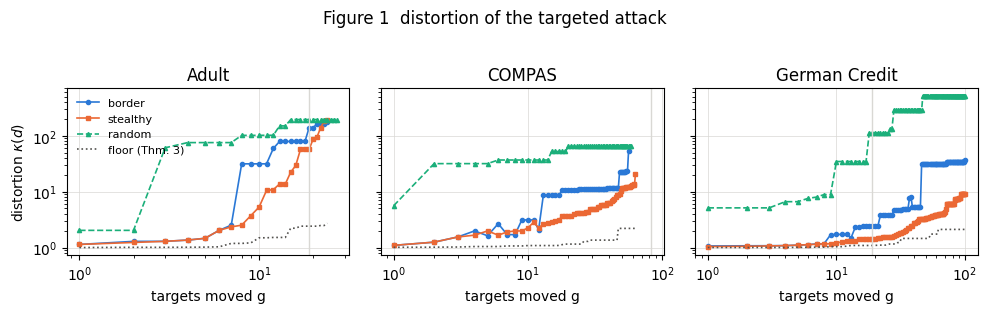

In [15]:
import json, numpy as np
import matplotlib.pyplot as plt
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
STYLE = {"border": (BLUE, "o", "-"), "stealthy": (ORANGE, "s", "-"), "random": (AQUA, "^", "--")}

# --- Figure 1: distortion vs number of moved targets ---
e3 = json.load(open("../results/e3.json"))
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, info in zip(axes, e3["info"]):
    ds = info["dataset"]
    for strat, (col, mk, ls) in STYLE.items():
        rows = sorted([r for r in e3["rows"] if r["dataset"] == ds and r["strategy"] == strat], key=lambda r: r["g"])
        ax.plot([r["g"] for r in rows], [r["distortion"] for r in rows], ls, color=col,
                marker=mk, ms=3, lw=1.2, label=strat)
    rows = sorted([r for r in e3["rows"] if r["dataset"] == ds and r["strategy"] == "stealthy"], key=lambda r: r["g"])
    ax.plot([r["g"] for r in rows], [r["lower_bound"] for r in rows], ":", color=MUTED, lw=1.2, label="floor (Thm. 3)")
    ax.axvline(info["g_res"], color=GRID, lw=1)
    ax.set(xscale="log", yscale="log", title=ds, xlabel="targets moved g")
    ax.grid(True, which="major", color=GRID, lw=0.5)
axes[0].set_ylabel(r"distortion $\kappa(d)$")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Figure 1  distortion of the targeted attack", y=1.03); fig.tight_layout(); plt.show()

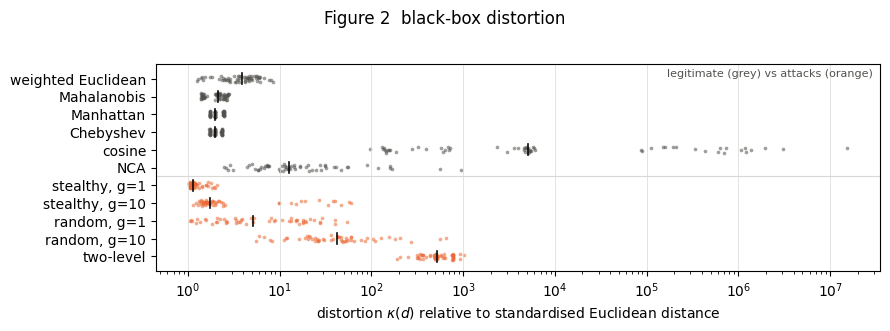

In [16]:
# --- Figure 2: distortion of benign metrics vs attacks ---
e4 = json.load(open("../results/e4.json")); rows = e4["rows"]
fams = ["weighted Euclidean","Mahalanobis","Manhattan","Chebyshev","cosine","NCA"]
atk = [("relocation-stealthy-g1","stealthy, g=1"), ("relocation-stealthy-g10","stealthy, g=10"),
       ("relocation-random-g1","random, g=1"), ("relocation-random-g10","random, g=10"),
       ("two-level (random labels)","two-level")]
labels = fams + [a[1] for a in atk]
data = [[np.exp(r["distort"]) for r in rows if r["variant"] == f] for f in fams] + \
       [[np.exp(r["distort"]) for r in rows if r["variant"] == a[0]] for a in atk]
fig, ax = plt.subplots(figsize=(9, 3.2)); rng = np.random.default_rng(0)
for i, vals in enumerate(data):
    col = MUTED if i < len(fams) else ORANGE
    y = len(data) - 1 - i
    ax.scatter(vals, y + rng.uniform(-.18, .18, len(vals)), s=7, color=col, alpha=.55, lw=0)
    ax.plot([np.median(vals)]*2, [y-.3, y+.3], color=INK, lw=1.2)
ax.set_yticks(range(len(data))); ax.set_yticklabels(labels[::-1])
ax.axhline(len(atk)-.5, color=GRID, lw=.8); ax.set_xscale("log")
ax.set_xlabel(r"distortion $\kappa(d)$ relative to standardised Euclidean distance")
ax.grid(True, axis="x", color=GRID, lw=.5)
ax.text(.99, .98, "legitimate (grey) vs attacks (orange)", transform=ax.transAxes, ha="right", va="top",
        fontsize=8, color=MUTED)
fig.suptitle("Figure 2  black-box distortion", y=1.02); fig.tight_layout(); plt.show()